<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%204/MRayhanZamzami_JS04_T2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS PRAKTIKUM - TUGAS 2

## Tugas 2

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

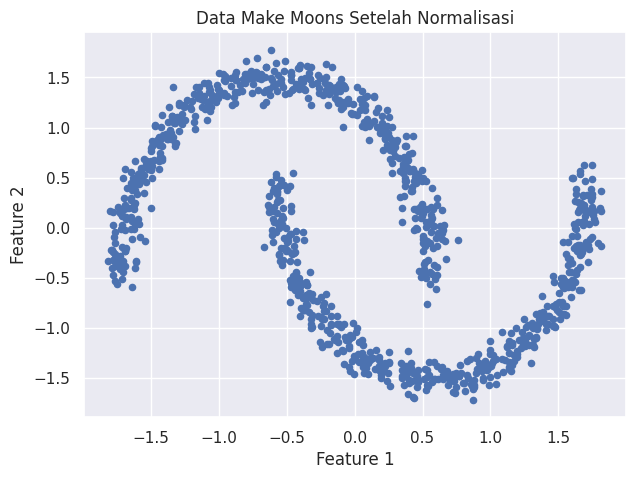

In [66]:
X, y_true = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=0
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=20)
plt.title('Data Make Moons Setelah Normalisasi')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

In [67]:
dbscan = DBSCAN(
    eps=0.2,
    min_samples=5
)

hasil_cluster = dbscan.fit_predict(X_scaled)

In [68]:
cluster_ids = set(hasil_cluster)

jumlah_cluster = len(cluster_ids - {-1})
jumlah_noise = np.sum(hasil_cluster == -1)

print("Jumlah cluster :", jumlah_cluster)
print("Jumlah noise   :", jumlah_noise)

Jumlah cluster : 2
Jumlah noise   : 0


In [69]:
homogeneity = metrics.homogeneity_score(y_true, hasil_cluster)
completeness = metrics.completeness_score(y_true, hasil_cluster)
v_measure = metrics.v_measure_score(y_true, hasil_cluster)
ari = metrics.adjusted_rand_score(y_true, hasil_cluster)
ami = metrics.adjusted_mutual_info_score(y_true, hasil_cluster)

if jumlah_cluster >= 2:
    silhouette = metrics.silhouette_score(X_scaled, hasil_cluster)
else:
    silhouette = np.nan

print(f"Homogeneity : {homogeneity:.3f}")
print(f"Completeness: {completeness:.3f}")
print(f"V-measure   : {v_measure:.3f}")
print(f"ARI         : {ari:.3f}")
print(f"AMI         : {ami:.3f}")
print(f"Silhouette  : {silhouette:.3f}")

Homogeneity : 1.000
Completeness: 1.000
V-measure   : 1.000
ARI         : 1.000
AMI         : 1.000
Silhouette  : 0.392


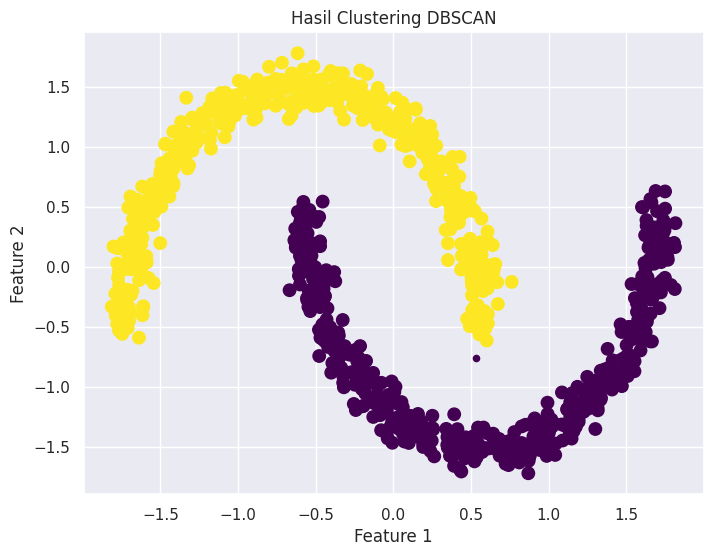

In [70]:
core_mask = np.zeros(hasil_cluster.shape, dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

noise_mask = hasil_cluster == -1
noncore_mask = (~core_mask) & (~noise_mask)

plt.figure(figsize=(8, 6))

# Non-core
plt.scatter(
    X_scaled[noncore_mask, 0],
    X_scaled[noncore_mask, 1],
    s=20,
    c=hasil_cluster[noncore_mask],
    cmap='viridis'
)

# Core
plt.scatter(
    X_scaled[core_mask, 0],
    X_scaled[core_mask, 1],
    s=80,
    c=hasil_cluster[core_mask],
    cmap='viridis'
)

# Noise
plt.scatter(
    X_scaled[noise_mask, 0],
    X_scaled[noise_mask, 1],
    s=25,
    c='black'
)

plt.title('Hasil Clustering DBSCAN')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

In [71]:
daftar_eps = [0.05, 0.1, 0.3, 0.5]
daftar_min_samples = [3, 10, 20]

hasil_pengujian = []

for nilai_eps in daftar_eps:
    for nilai_min in daftar_min_samples:

        model = DBSCAN(
            eps=nilai_eps,
            min_samples=nilai_min
        )

        prediksi = model.fit_predict(X_scaled)

        cluster_terbentuk = len(set(prediksi) - {-1})
        noise_terdeteksi = np.sum(prediksi == -1)

        hom = metrics.homogeneity_score(y_true, prediksi)
        comp = metrics.completeness_score(y_true, prediksi)
        v = metrics.v_measure_score(y_true, prediksi)
        ari_value = metrics.adjusted_rand_score(y_true, prediksi)
        ami_value = metrics.adjusted_mutual_info_score(y_true, prediksi)

        if cluster_terbentuk >= 2:
            sil = metrics.silhouette_score(X_scaled, prediksi)
        else:
            sil = np.nan

        hasil_pengujian.append({
            'eps': nilai_eps,
            'min_samples': nilai_min,
            'clusters': cluster_terbentuk,
            'noise': noise_terdeteksi,
            'homogeneity': hom,
            'completeness': comp,
            'v_measure': v,
            'ARI': ari_value,
            'AMI': ami_value,
            'silhouette': sil
        })

In [73]:
tabel_hasil.round(3)

,eps,min_samples,clusters,noise,homogeneity,completeness,v_measure,ARI,AMI,silhouette
0,0.05,3,67,197,0.804,0.155,0.260,0.033,0.246,0.078
1,0.05,10,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
2,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
3,0.10,3,3,18,0.983,0.708,0.824,0.854,0.823,0.138
4,0.10,10,9,63,0.939,0.358,0.519,0.435,0.517,0.184
5,0.10,20,6,844,0.157,0.153,0.155,0.010,0.152,-0.409
6,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.392
7,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.392
8,0.30,20,2,0,1.000,1.000,1.000,1.000,1.000,0.392
9,0.50,3,1,0,0.000,1.000,0.000,0.000,0.000,NaN
